# Chapter 33: Vector Representations — Visualizing Embeddings


What you will learn
Your embedding model converts each sentence into 384 numbers. These numbers represent the sentence in a high-dimensional space, which we cannot directly visualize.
We'll use PCA (Principal Component Analysis) to reduce those 384 dimensions to 2, then plot the sentences.

In [ ]:
# Install required libraries
%pip install -U sentence-transformers scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


# Generate embeddings for sample sentences 

In [4]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

texts = [
    "I love machine learning",
    "Artificial intelligence is fascinating",
    "Deep learning trains neural networks",
    "I enjoy playing cricket",
    "Football is a popular sport",
    "The cricket team won the match",
    "Python is useful for data science",
    "Data science uses machine learning"
]

embeddings = model.encode(texts)

In [5]:
print(embeddings.shape)

(8, 384)


# Reduce 384 dimensions to 2 using PCA

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

vectors_2d = pca.fit_transform(embeddings)

print("Original shape:", embeddings.shape)
print("Reduced shape:", vectors_2d.shape)

Original shape: (8, 384)
Reduced shape: (8, 2)


In [8]:
# explained_variance_ratio_.sum(): shows how much of the original variance the two dimensions retain.
print(pca.explained_variance_ratio_.sum())

0.50049835


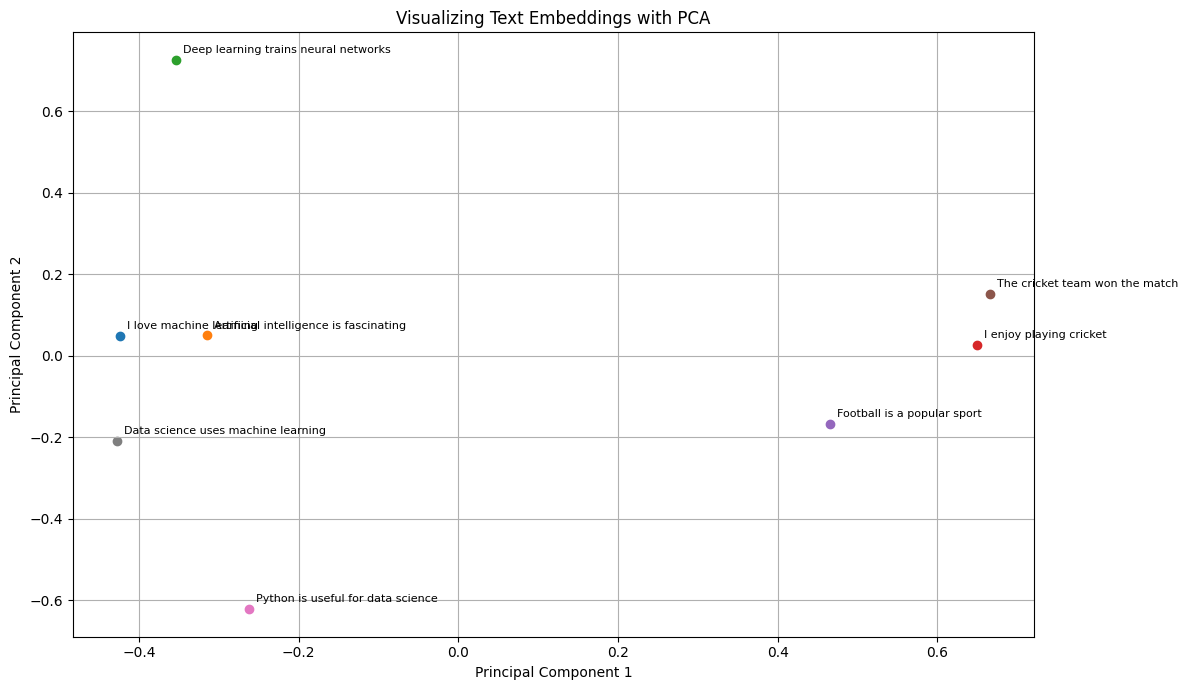

In [14]:
# Plot the sentence vectors

import matplotlib.pyplot as plt

plt.figure(figsize =(12,7))

for i, text in enumerate(texts):
    x = vectors_2d[i,0]
    y = vectors_2d[i,1]

    plt.scatter(x,y)
    plt.annotate(text,(x,y),
                 xytext =(5,5),
                 textcoords = "offset points",
                 fontsize = 8)


plt.title("Visualizing Text Embeddings with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

Understand the result
- Sentences about cricket and football may appear near one another.
- Sentences about machine learning and data science may also cluster.
- Related sentences do not have to appear next to each other in every 2D plot.
PCA compresses 384 dimensions into just two, so some relationships will be distorted. The plot is a useful visualization, not proof that the model understands every sentence correctly.